In [1]:
import pandas as pd
import matplotlib.pyplot as pl
import seaborn as sns
from sklearn.linear_model import LogisticRegression
import numpy as np
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv('loan_approval_nepal_clean.csv')

In [3]:
df['loan_status'].value_counts()

loan_status
Approved    25
Rejected    25
Name: count, dtype: int64

In [40]:
df1 = df[['monthly_income_npr','credit_score','loan_status']]

In [41]:
X = df1[['monthly_income_npr','credit_score']]

In [42]:
y = df1['loan_status'].map({'Approved':1,'Rejected':0})

<Axes: xlabel='monthly_income_npr', ylabel='credit_score'>

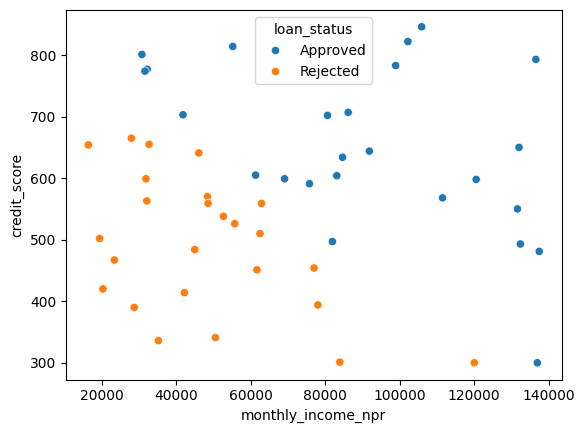

In [43]:
sns.scatterplot(x=df1['monthly_income_npr'],y=df1['credit_score'],hue=df1['loan_status'])
# sns.plot(ax+by+c)

In [44]:
model = LogisticRegression()

In [45]:
model.fit(X,y)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [46]:
model.coef_

array([[0.00188051, 0.40824018]])

In [47]:
model.intercept_

array([-352.96366219])

In [48]:
-0.00188051*137009+300*-0.40824018+352.96366219  #Approad

-27.155186400000048

In [49]:
-0.00188051*83911+301*-0.40824018+352.96366219  #Rejected

72.28789339999997

In [50]:
a=0.00188051
b=0.40824018
c=-352.96366219

In [51]:
model.predict([[76985,454]])

array([0])

In [52]:
x = np.linspace(
    df1['monthly_income_npr'].min(),
    df1['monthly_income_npr'].max(),
    100
)

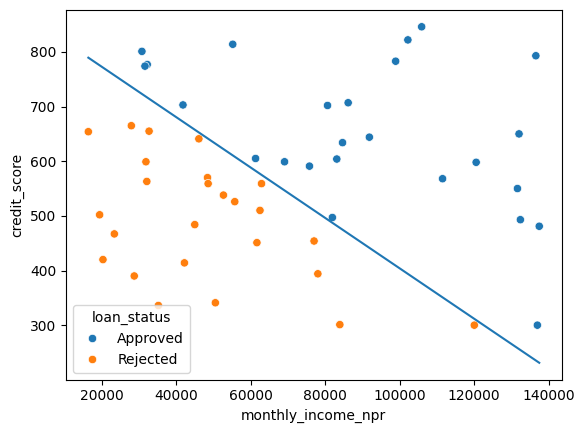

In [53]:
y = (-a * x - c) / b
sns.scatterplot(x=df1['monthly_income_npr'],y=df1['credit_score'],hue=df1['loan_status'])
pl.plot(x, y)

In [54]:
df_2 = pd.read_csv('loan_approval_nepal_clean_v2.csv')

In [55]:
df_2

,name,age,monthly_income_npr,credit_score,existing_loans,loan_status
0,Purnima Bhandari,28,31049,357,1,Not Approved
1,Laxmi Yadav,55,17082,307,1,Not Approved
2,Bikram Bogati,53,50713,407,1,Not Approved
3,Devi Ghimire,38,25463,478,2,Not Approved
4,Ram Bhandari,30,72059,516,1,Hold
...,...,...,...,...,...,...
65,Rajan Sapkota,58,43977,472,1,Not Approved
66,Devi Poudel,31,123506,812,2,Approved
67,Bishnu Khadka,36,93050,687,0,Approved
68,Khem Subedi,51,52727,349,3,Not Approved


In [56]:
df_2 = df_2[['monthly_income_npr','credit_score','loan_status']]

In [57]:
X1 = df_2[['monthly_income_npr','credit_score']]

In [58]:
y = df_2['loan_status']

sns.scatterplot(x=df1['monthly_income_npr'],y=df1['credit_score'],hue=df1['loan_status'])
# sns.plot(ax+by+c)

In [59]:
model = LogisticRegression()

In [60]:
model.fit(X1,y)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [61]:
model.coef_

array([[ 0.00214065,  0.14880888],
       [ 0.00029949,  0.02061706],
       [-0.00244014, -0.16942607]])

In [62]:
model.intercept_

array([-234.71329496,   -1.34093913,  236.0542341 ])

In [63]:
a1=0.00188051
b1=0.40824018
c=-352.96366219

In [64]:
# y = (-a * x - c) / b
# sns.scatterplot(x=df_2['moanthly_income_npr'],y=df_2['credit_score'],hue=df_2['loan_status'])
# # pl.plot(x, y)

In [65]:
X_train, X_test, y_train, y_test = train_test_split(
    X1,
    y,
    test_size=0.2,
    random_state=42
)

In [66]:
model.classes_

array(['Approved', 'Hold', 'Not Approved'], dtype=object)

In [67]:
model.coef_

array([[ 0.00214065,  0.14880888],
       [ 0.00029949,  0.02061706],
       [-0.00244014, -0.16942607]])

In [68]:
model.intercept_

array([-234.71329496,   -1.34093913,  236.0542341 ])

In [69]:
model.predict([[123506,812]])


array(['Approved'], dtype=object)

In [70]:
model.predict_proba([[123506,812]])

array([[1.00000000e+000, 2.45308414e-043, 3.33316088e-154]])

In [71]:
1.00000000e+000

1.0

In [72]:
round(2.45308414e-043)

0